# Supplementary Figure S8d. LoF-constrained gene enrichment of genes at *cis*-only, *cis*-*trans* and *trans*-only loci

Enrichment of loss-of-function-constrained genes (gnomAD v2.1.1 pLI ≥ 0.9, 3,060 genes) among genes with the nearest TSS to *cis*-only, *cis*-*trans* and *trans*-only colocalized loci, and among the *cis*-eGenes of *cis*-only and *cis*-*trans* loci, shown separately for *trans*-eGene (top) and *trans*-eProgram (bottom). Enrichment is the odds ratio from a 2×2 table of the query genes vs the gene set, with all 18,968 autosomal protein-coding genes (Ensembl 103) as background. Error bars are OR ± 1.96 × SE, with SE = OR·sqrt(1/a+1/b+1/c+1/d) (delta method, symmetric on the OR scale; these are not leave-one-chromosome-out jackknife intervals). P-values are two-sided Wald tests of OR = 1 using the same SE; asterisks mark Benjamini-Hochberg FDR < 5%, with BH applied across the 10 tests (5 categories × TF and pLI gene sets) within each *trans* method. Loci are the main-Figure-3a filtered set (all *cis*-eQTL loci; *trans* loci only if they also colocalize with a biomarker-QTL), split by *trans*-eGene or *trans*-eProgram, as in the published figure.

**Difference from the published panel:** the author's plotting code applied a hard-coded "manual correction" to the transcription-factor rows: it halved the SE of the *trans*-only (nearest TSS) row, which narrows its CI two-fold; it forced a star on that row; and it removed the stars of the other nearest-TSS rows. This notebook shows the uncorrected test results instead. The *trans*-only TF rows remain significant (BH FDR 4.9e-5 for eGene, 2.4e-3 for eProgram) with wider CIs, and *cis*-only (nearest TSS genes) is significant (FDR 0.043) in both methods. The pLI rows were not altered by the author.

Input: `data/Figure_S8d_pli_enrichment.rds`.

In [1]:
library(ggplot2)
d <- readRDS("data/Figure_S8d_pli_enrichment.rds")
d[, c("trans_method", "category", "n_query", "n_overlap", "odds_ratio", "ci_low", "ci_high", "p_value", "p_adj")]

,trans_method,category,n_query,n_overlap,odds_ratio,ci_low,ci_high,p_value,p_adj
,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
6,trans-eGene,cis-trans (nearest TSS),3323,483,1.0295471,0.9199866,1.139108,5.970913e-01,5.970913e-01
7,trans-eGene,trans-only (nearest TSS),9736,1670,1.6468969,1.5093918,1.784402,2.946679e-20,2.946679e-19
8,trans-eGene,cis-only (nearest TSS),7730,1057,0.9243826,0.8473350,1.001430,5.440271e-02,9.067119e-02
9,trans-eGene,cis-only (eGene),8190,1131,0.9396910,0.8621740,1.017208,1.272844e-01,1.591055e-01
10,trans-eGene,cis-trans (eGene),2204,326,1.0516931,0.9198570,1.183529,4.421793e-01,4.913103e-01
16,trans-eProgram,cis-trans (nearest TSS),2703,409,1.0869384,0.9629211,1.210956,1.694429e-01,1.882699e-01
17,trans-eProgram,trans-only (nearest TSS),8241,1438,1.5839074,1.4544164,1.713398,9.733434e-19,9.733434e-18
18,trans-eProgram,cis-only (nearest TSS),7730,1057,0.9243826,0.8473350,1.001430,5.440271e-02,7.771816e-02
19,trans-eProgram,cis-only (eGene),8190,1131,0.9396910,0.8621740,1.017208,1.272844e-01,1.591055e-01


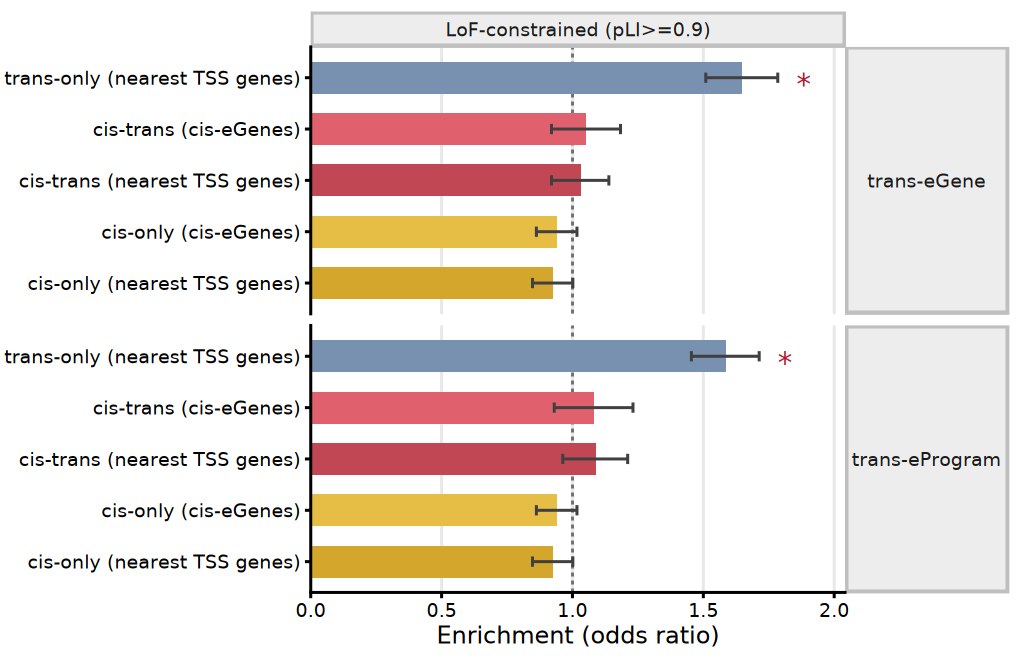

In [2]:
cat_levels <- c("cis-only (nearest TSS)", "cis-only (eGene)", "cis-trans (nearest TSS)",
                "cis-trans (eGene)", "trans-only (nearest TSS)")
cat_colors <- c("cis-only (nearest TSS)" = "#D4A72C", "cis-only (eGene)" = "#E6BE46",
                "cis-trans (nearest TSS)" = "#C24755", "cis-trans (eGene)" = "#E0616D",
                "trans-only (nearest TSS)" = "#7991B1")
cat_labels <- c("cis-only (nearest TSS)" = "cis-only (nearest TSS genes)",
                "cis-only (eGene)" = "cis-only (cis-eGenes)",
                "cis-trans (nearest TSS)" = "cis-trans (nearest TSS genes)",
                "cis-trans (eGene)" = "cis-trans (cis-eGenes)",
                "trans-only (nearest TSS)" = "trans-only (nearest TSS genes)")
d$category <- factor(d$category, levels = cat_levels)
d$star     <- ifelse(d$significant_fdr05, "*", "")
pad <- 0.04 * max(d$ci_high)

p <- ggplot(d, aes(y = category, x = odds_ratio, fill = category)) +
  geom_vline(xintercept = 1, linetype = "dashed", color = "grey45") +
  geom_col(width = 0.6, orientation = "y") +
  geom_errorbar(aes(xmin = ci_low, xmax = ci_high), width = 0.2, orientation = "y", color = "grey25") +
  geom_text(aes(x = ci_high + pad, label = star), color = "#B2182B", size = 6, hjust = 0, vjust = 0.75) +
  facet_grid(rows = vars(trans_method), cols = vars(gene_set)) +
  scale_y_discrete(labels = cat_labels) +
  scale_fill_manual(values = cat_colors, guide = "none") +
  scale_x_continuous(expand = expansion(mult = c(0, 0.1))) +
  labs(x = "Enrichment (odds ratio)", y = NULL) +
  theme_classic(base_size = 14) +
  theme(strip.background = element_rect(fill = "grey93", color = "grey75"),
        strip.text.y = element_text(angle = 0),
        panel.grid.major.x = element_line(color = "grey91"))

options(repr.plot.width = 8.5, repr.plot.height = 5.5)
p